In [1]:
import os
import sys
import requests
import datetime as dt
import numpy as np
from dotenv import load_dotenv
from pathlib import Path
import requests
import pandas as pd
import talib as ta
import plotly.graph_objs as go

import ipywidgets as widgets
from ipywidgets import Dropdown, Text, Button, Output
from IPython.display import display

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.reques_api import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension

In [2]:
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()

### WTIの時系列データを取得

In [3]:
wti = 'CL=F'
start = '1999-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
response = request_api.update_commodity_timeseries_data(
    code=wti,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [4]:
wti_df = request_api.get_commodity_time_series_data(
    code=wti,
    market=None,
    start=start,
    end=end
)
wti_df.head()

取得件数: 6564


,id,commodity_id,commodity_code,commodity_market,date,open,high,low,close,adj_close,...,rci26,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,6530,2,CL=F,None,2000-08-23,32.049999,32.799999,31.950001,31.950001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,6531,2,CL=F,None,2000-08-24,31.629999,32.240002,31.400000,31.900000,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,6532,2,CL=F,None,2000-08-25,32.049999,32.099998,31.320000,31.700001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,6533,2,CL=F,None,2000-08-28,32.869999,32.919998,31.860001,32.040001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,6534,2,CL=F,None,2000-08-29,32.720001,33.029999,32.560001,32.820000,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### S&P500の時系列データを取得

In [5]:
sp500 = '^GSPC'

response = request_api.update_stock_timeseries_data(
    code=sp500,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [6]:
sp_timeseries_df = request_api.get_stock_time_series_data(
    code=sp500,
    market=None,
    start=start,
    end=end
)
sp_timeseries_df.head()

取得件数: 7018


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1064856,^GSPC,None,1998-11-17,1139.319946,1151.709961,1129.670044,1135.869995,705200000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1064857,^GSPC,None,1998-11-18,1144.479980,1144.520020,1133.069946,1139.319946,652510000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1064858,^GSPC,None,1998-11-19,1152.609985,1155.099976,1144.420044,1144.479980,671000000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1064859,^GSPC,None,1998-11-20,1163.550049,1163.550049,1152.609985,1152.609985,721200000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1064860,^GSPC,None,1998-11-23,1188.209961,1188.209961,1163.550049,1163.550049,774100000,1147.165991,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### XOMの時系列データを取得

In [7]:
xom = 'XOM'

response = request_api.update_stock_timeseries_data(
    code=xom,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [8]:
xom_timeseries_df = request_api.get_stock_time_series_data(
    code=xom,
    market=None,
    start=start,
    end=end
)
xom_timeseries_df

取得件数: 7018


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1071850,XOM,None,1998-11-17,14.915026,15.311351,14.901815,15.047134,5074400,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1071851,XOM,None,1998-11-18,14.941448,15.007502,14.756497,14.875394,6623200,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1071852,XOM,None,1998-11-19,14.769705,14.994289,14.703651,14.941446,6319600,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1071853,XOM,None,1998-11-20,15.218869,15.245291,14.822544,14.901809,9908600,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1071854,XOM,None,1998-11-23,15.232084,15.324560,14.994289,15.258506,6427800,15.004858,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7013,1268159,XOM,None,2026-10-07,164.050003,166.860001,163.460007,165.600006,9516200,163.094000,...,160.350357,59.177837,True,163.094,NaN,0.759498,NaN,NaN,NaN,False
7014,1268160,XOM,None,2026-10-08,168.500000,169.190002,166.710007,167.110001,13288100,164.216000,...,160.353736,59.015624,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7015,1268161,XOM,None,2026-10-09,168.940002,170.289993,167.820007,167.869995,8083600,165.479999,...,160.339256,59.024161,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7016,1268162,XOM,None,2026-10-12,172.149994,172.550003,171.009995,171.009995,8811000,166.929999,...,160.387753,59.519337,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### チャート

In [9]:
def stock_prices_and_oil_prices(
        code: str,
        name: str,
        start: str,
        end: str,
        df_sp: pd.DataFrame | None = None,
        df_wti: pd.DataFrame | None = None,
        #df_silver: pd.DataFrame | None = None,
    ):
    # /api/v1/time_series_data/stock/
    response = request_api.get_stock_time_series_data(
        code=code,
        market=None,
        start=start,
        end=end
    )
    df_stock = pd.DataFrame(response)

    # S&P500を統合
    if df_sp is not None:
        df_sp_tmp = df_sp.copy() if df_sp is not None else pd.DataFrame()
        if "date" not in df_sp_tmp.columns:
            df_sp_tmp = df_sp_tmp.reset_index()

        df_sp_tmp["date"] = pd.to_datetime(df_sp_tmp["date"])
        df_sp_tmp = df_sp_tmp.set_index("date")
        df_sp_tmp = df_sp_tmp.loc[start:end]

    # WTI原油価格を統合
    if df_wti is not None:
        df_wti_tmp = df_wti.copy() if df_wti is not None else pd.DataFrame()
        if "date" not in df_wti_tmp.columns:
            df_wti_tmp = df_wti_tmp.reset_index()
        df_wti_tmp["date"] = pd.to_datetime(df_wti_tmp["date"])
        df_wti_tmp = df_wti_tmp.set_index("date")
        df_wti_tmp = df_wti_tmp.loc[start:end]

    # 株価時系列データを整形
    df = df_stock.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")
    df = df.loc[start:end]


    # インデックスを揃えて結合
    if df_sp is not None:
        df["MA50_SP"] = df_sp_tmp["ma50"].reindex(df.index)
        df["MA200_SP"] = df_sp_tmp["ma200"].reindex(df.index)
    if df_wti is not None:
        df["MA50_WTI"] = df_wti_tmp["ma50"].reindex(df.index)
        df["MA200_WTI"] = df_wti_tmp["ma200"].reindex(df.index)

    show_plot = ShowPlot()
    fig = show_plot.create_basic_chart(
        df=df.reset_index(),
        code=code,
        name=name,
        start=start,
        end=end,
        ma5=False,
        ma25=False,
        ma50=True,
        ma100=False,
        ma150=False,
        ma200=True,
    )
    # ★ 2つのY軸を定義（左：HYMC、右：SP500 & GOLD）
    fig.update_layout(
        yaxis=dict(
            title=f"{name} Price",
            side="left"
        ),
        yaxis2=dict(
            title="SP500 / WTI",
            overlaying="y",
            side="right"
        )
    )

    # --- SP500（右軸） ---
    if df_sp is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_SP"],
                name="SP_MA50",
                line={"color": "blue", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_SP"],
                name="SP_MA200",
                line={"color": "gray", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    # --- WTI（右軸） ---
    if df_wti is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_WTI"],
                name="WTI_MA50",
                line={"color": "orange", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_WTI"],
                name="WTI_MA200",
                line={"color": "yellow", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    return fig

In [10]:
name = "Exxonmobil Holdings Corp"
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_oil_prices(
    code=xom,
    name=name,
    start=start,
    end=end,
    df_sp=None,
    df_wti=wti_df
)
fig.show()

取得件数: 653


In [ ]:
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"{xom}_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
fig.write_image(str(output_path), width=1600, height=900, scale=2)
# 保存完了のメッセージを表示
print("saved:", output_path)

saved: /workspace/data/figures/XOM_2025-01-01_2026-10-14.png


#### 株価のみのチャート

In [12]:
name = "Exxonmobil Holdings Corp"
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
#end = dt.datetime(2026, 4, 17).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_oil_prices(
    code=xom,
    name=name,
    start=start,
    end=end,
    df_sp=None,
    df_wti=None
)
fig.show()

取得件数: 653


### WTI

In [13]:
name = "WTI指数"
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_oil_prices(
    code=wti,
    name=name,
    start=start,
    end=end,
    df_sp=None,
    df_wti=None
)
fig.show()

取得件数: 654


In [ ]:
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True
# ファイル名にコードと期間を含める
output_path = output_dir / f"{wti}_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
fig.write_image(str(output_path), width=1600, height=900, scale=2)
# 保存完了のメッセージを表示
print("saved:", output_path)

saved: /workspace/data/figures/CL=F_2025-01-01_2026-10-14.png


#### 時系列データを保存

In [ ]:
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{xom}_data_{dt.datetime.now().strftime("%Y-%m-%d")}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = xom_timeseries_df.copy()
df = df.reset_index()
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")
df = df.loc['2026-01-01':end]
df.to_csv(output_path)
df.head()

,index,id,stock_code,stock_market,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
date,,,,,,,,,,,,,,,,,,,,,
2026-01-02,6822,1078672,XOM,None,120.237953,120.267362,117.257737,117.728293,14175100,117.916520,...,113.590472,73.217792,True,NaN,NaN,NaN,NaN,NaN,77.846154,False
2026-01-05,6823,1078673,XOM,None,122.894653,123.453443,119.983061,122.747602,30112200,119.155661,...,113.632137,73.217792,True,NaN,NaN,NaN,3.996646,NaN,NaN,False
2026-01-06,6824,1078674,XOM,None,118.669426,123.326012,118.620406,122.884857,23328600,120.175209,...,113.739585,73.217792,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-07,6825,1078675,XOM,None,116.159760,117.757709,115.944085,117.444002,20353000,119.920322,...,113.925066,73.115342,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-08,6826,1078676,XOM,None,120.492844,121.198678,116.326425,116.640131,20232700,119.488977,...,114.067405,73.866644,True,NaN,16.382198,NaN,NaN,NaN,NaN,False


In [ ]:
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{wti}_data_{dt.datetime.now().strftime("%Y-%m-%d")}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
df = wti_df.copy()
df = df.reset_index()
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")
df = df.loc['2026-01-01':end]
df.to_csv(output_path)
df.head()

,index,id,commodity_id,commodity_code,commodity_market,open,high,low,close,adj_close,...,rci26,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
date,,,,,,,,,,,,,,,,,,,,,
2026-01-02,6367,12897,2,CL=F,None,57.320000,57.930000,56.599998,57.410000,None,...,-62.837607,-62.080594,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-05,6368,12898,2,CL=F,None,58.320000,58.509998,56.310001,57.470001,None,...,-61.880342,-69.525314,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-06,6369,12899,2,CL=F,None,57.130001,58.869999,56.840000,58.340000,None,...,-61.059829,-76.893196,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-07,6370,12900,2,CL=F,None,55.990002,57.169998,55.759998,57.000000,None,...,-59.623932,-84.465978,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-08,6371,12901,2,CL=F,None,57.759998,58.740002,55.970001,56.419998,None,...,-58.871795,-85.336805,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### Fibonacci Extension

{'fib_levels_down': {'1.000': np.float64(67.04000091552734),
  '1.272': np.float64(55.10192108154297),
  '1.382': np.float64(50.27402114868164),
  '1.618': np.float64(39.91598129272461)},
 'fib_levels_up': {'1.272': np.float64(122.86808013916016),
  '1.382': np.float64(127.69598007202148),
  '1.618': np.float64(138.05401992797852),
  '2.000': np.float64(154.81999969482422)},
 'swing_high': np.float64(110.93000030517578),
 'swing_low': np.float64(67.04000091552734),
 'df_with_fib':           date  index      id  commodity_id commodity_code commodity_market  \
 0   2026-01-02   6367   12897             2           CL=F             None   
 1   2026-01-05   6368   12898             2           CL=F             None   
 2   2026-01-06   6369   12899             2           CL=F             None   
 3   2026-01-07   6370   12900             2           CL=F             None   
 4   2026-01-08   6371   12901             2           CL=F             None   
 ..         ...    ...     ...     

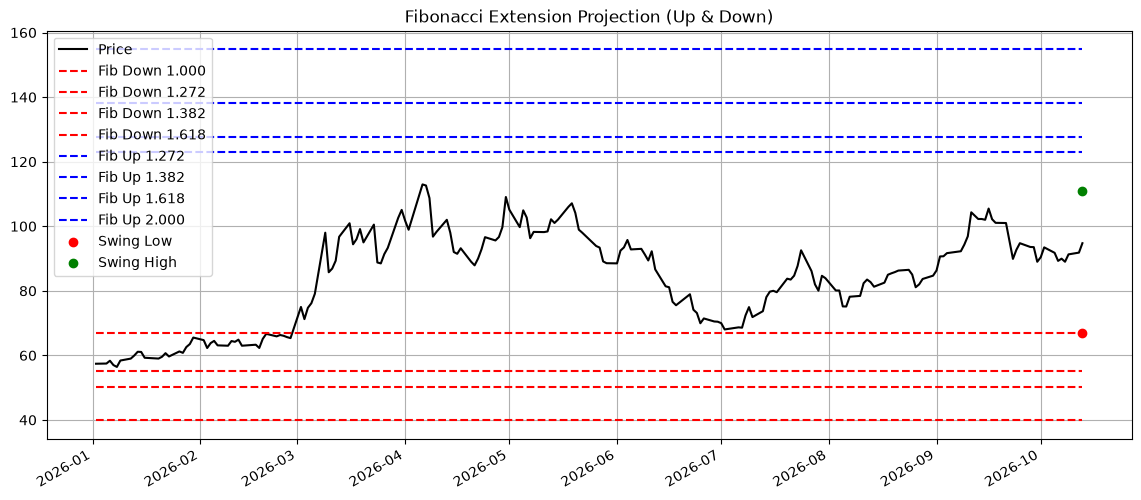

In [17]:
fib_result = fibonacci_extension.compute_fibonacci_extension(df.copy().reset_index())
fib_result

In [ ]:
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{xom}_fibonacci_extension_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
fib_result["plot_obj"].savefig(output_path, dpi=300, bbox_inches="tight")
# 保存完了のメッセージを表示
print("saved:", output_path)

#### 財務データ

In [19]:
response = request_api.update_corp_finance_data(
    code=xom,
    market=None
)
response

{'result': True}

In [20]:
xom_financials_data = request_api.get_corp_financials_data(code=xom, market=None)
xom_balance_sheet_data = request_api.get_corp_balance_sheet_data(code=xom, market=None)
xom_cash_flow_data = request_api.get_corp_cash_flow_data(code=xom, market=None)
xom_earnings_data = request_api.get_corp_earnings_data(code=xom, market=None)
xom_quarterly_earnings_data = request_api.get_corp_quarterly_earnings_data(code=xom, market=None)

In [21]:
# ４年分の財務データ
xom_financials_data_df = pd.DataFrame(xom_financials_data['results'])
# ４年分のバランスシート
xom_balance_sheet_data_df = pd.DataFrame(xom_balance_sheet_data['results'])
# ４年分のキャッシュフロー
xom_cash_flow_data_df = pd.DataFrame(xom_cash_flow_data['results'])
# ４年分の収益データ
xom_earnings_data_df = pd.DataFrame(xom_earnings_data['results'])
# ４年分の四半期収益データ
xom_quarterly_earnings_data_df = pd.DataFrame(xom_quarterly_earnings_data['results'])

In [22]:
"""
◆ 1. 株価・市場データ
• 現在株価（Price）
• 時価総額（Market Cap）
• 出来高（Volume）
• 52週高値・安値
• Beta（ボラティリティ指標）ß
"""
stock_prices_market_data.stock_prices_and_market_data(
    code=xom,
    market=None,
    bs_df=xom_balance_sheet_data_df
)

取得件数: 460
取得件数: 460
取得件数: 458
取得件数: 458
取得件数: 459
取得件数: 459
取得件数: 458
取得件数: 458


,close,market_cap,shares_outstanding,higher_rate_par_52_weeks,lower_rate_par_52_weeks,beta
0,50.178067,4.023779e+11,8.019000e+09,101.369907,43.723727,0.578678
1,76.577167,6.140723e+11,8.019000e+09,109.372212,65.569991,0.648486
2,98.790665,7.922117e+11,8.019095e+09,118.496951,87.340660,0.371499
3,99.907592,8.011590e+11,8.019000e+09,119.404671,93.309649,0.477930


In [23]:
"""
◆ 2. 財務データ（Financials）+ EPS（Earnings Per Share）+ PBR（Price-to-Book Ratio）
• 売上高（Revenue）
• 営業利益（Operating Income）
• 純利益（Net Income）
• EBITDA（企業による）
• 総資産（Total Assets）
• 総負債（Total Liabilities）
• 現金（Cash）
• 希釈EPS（Diluted EPS）
• 基本EPS（Basic EPS）
• 営業キャッシュフロー（Operating Cash Flow）
• フリーキャッシュフロー（Free Cash Flow）
"""
financial_df = financial.calc_financial(
    code = xom,
    market = None,
)
financial_df.to_markdown()

取得件数: 6944


'|    | date                |       revenue |     earnings |   total_assets |   total_debt |   cash_and_cash_equivalents |      EBITDA |   operating_income |   basic_eps |   diluted_eps |   operating_cash_flow |   free_cash_flow |\n|---:|:--------------------|--------------:|-------------:|---------------:|-------------:|----------------------------:|------------:|-------------------:|------------:|--------------:|----------------------:|-----------------:|\n|  0 | 2021-12-31 00:00:00 | nan           | nan          |  nan           | nan          |                nan          | 0           |       nan          |      nan    |        nan    |          nan          |     nan          |\n|  1 | 2022-12-31 00:00:00 |   3.98675e+11 |   5.574e+10  |    3.69067e+11 |   4.1193e+10 |                  2.964e+10  | 1.02591e+11 |         6.4028e+10 |       13.26 |         13.26 |            7.6797e+10 |       5.839e+10  |\n|  2 | 2023-12-31 00:00:00 |   3.34697e+11 |   3.601e+10  |    3.76317e+11 